Correct structuring of the cells, removed duplicates and added explainations to functions whereever necessary.
- LiteLLM - model fallback integration

### Step 1: Project Setup

In [1]:
import os, json, time
from dotenv import load_dotenv

load_dotenv()

GEMINI_API_KEY      = os.getenv("GOOGLE_API_KEY")
GROQ_API_KEY        = os.getenv("GROQ_API_KEY")
OPENROUTER_API_KEY  = os.getenv("OPENROUTER_API_KEY")

print("Gemini key loaded    :   ", "✅" if GEMINI_API_KEY           else "❌ Missing!")
print("Groq key loaded      :   ", "✅" if GROQ_API_KEY             else "❌ Missing!")
print("OpenRouter key loaded:   ", "✅" if OPENROUTER_API_KEY       else "❌ Missing!")

Gemini key loaded    :    ✅
Groq key loaded      :    ✅
OpenRouter key loaded:    ✅


In [2]:
import litellm
from litellm import Router
from groq import Groq

litellm.drop_params = True   
# drop params a provider doesn't support (e.g. response_format) instead of raising

# ── Deployments ──────────────────────────────────────────────────────────────
GEMINI_MODEL     = "gemini/gemini-3.5-flash-lite"
GROQ_MODEL       = "groq/openai/gpt-oss-20b"
OPENROUTER_MODEL = "openrouter/nvidia/nemotron-3-ultra-550b-a55b:free"

def _dep(alias, model, api_key, **extra):
    return {"model_name": alias,
            "litellm_params": {"model": model, "api_key": api_key, "max_tokens": 2048, **extra}}

model_list = [
    # "tree-search" -> Step 1 (rules + whole tree, ~20K+ tokens).
    _dep("tree-search",     GEMINI_MODEL,     GEMINI_API_KEY,     timeout=5),
    _dep("tree-search-fb1", OPENROUTER_MODEL, OPENROUTER_API_KEY, timeout=8, reasoning_effort="low"),

    # "answer" -> Step 3 (in the Step 7 of this notebook)
    _dep("answer",          GEMINI_MODEL,     GEMINI_API_KEY,     timeout=4),
    _dep("answer-fb1",      GROQ_MODEL,       GROQ_API_KEY,       timeout=4, reasoning_effort="low"),
    _dep("answer-fb2",      OPENROUTER_MODEL, OPENROUTER_API_KEY, timeout=8, reasoning_effort="low"),
]

router = Router(
    model_list=model_list,
    fallbacks=[
        {"tree-search": ["tree-search-fb1"]},
        {"answer":      ["answer-fb1", "answer-fb2"]},
    ],
    num_retries=0,     # fail over immediately instead of re-trying the same provider (keeps latency low)
    allowed_fails=1,   # circuit breaker: after a failure
    cooldown_time=30,  # skip that deployment for 30s, so later queries don't pay the timeout again
)
print("✅ LiteLLM router ready  (Gemini primary → OpenRouter / Groq fallbacks)")

groq_client = Groq(api_key=GROQ_API_KEY)
print("✅ GROQ client ready")

✅ LiteLLM router ready  (Gemini primary → OpenRouter / Groq fallbacks)
✅ GROQ client ready


### Step 2: Index creation without any LLM

#### PageIndex's underlying Flash function without LLM summary

Instead of running PageIndexClient.submit_document() (which forces LLM summarization on every node), call PageIndex's underlying Flash function directly with summary=False. Using optimize="merge" (deterministic, LLM-free pass) or optimize=False builds the entire hierarchical tree purely from the PDF layout and bookmarks in seconds with zero Ollama calls and zero API rate limits.

**Run only once**

In [ ]:
import json
import time
from pathlib import Path
import fitz
import pymupdf
from pageindex.flash import page_index_flash

def build_fast_legal_index(corpus_dir: str = "../corpus", output_dir: str = "../legal_index",):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    manifest = {}

    for pdf_path in sorted(Path(corpus_dir).glob("*.pdf")):
        t0 = time.perf_counter()
        print(f"[INDEXING] {pdf_path.name} (zero-LLM Flash mode) ...")

        # Pure deterministic layout/bookmark tree - zero LLM calls
        tree = page_index_flash(
            str(pdf_path),
            summary=False,
            optimize="merge",  # use optimize=False if raw unmerged nodes is needed
        )

        # Save hierarchical tree JSON
        tree_file = out / f"{pdf_path.stem}_tree.json"
        tree_file.write_text(json.dumps(tree, indent=2, ensure_ascii=False), encoding="utf-8")

        # Extract & cache 1-indexed verbatim pages once for <5ms retrieval in LangGraph
        doc = fitz.open(pdf_path)
        pages = {str(i + 1): page.get_text("text") for i, page in enumerate(doc)}
        doc.close()

        pages_file = out / f"{pdf_path.stem}_pages.json"
        pages_file.write_text(json.dumps(pages, indent=2, ensure_ascii=False), encoding="utf-8")

        manifest[pdf_path.stem] = {
            "source_pdf": pdf_path.name,
            "page_count": len(pages),
            "tree_file": str(tree_file),
            "pages_file": str(pages_file),
        }
        print(f"[DONE] {pdf_path.name} ({len(pages)} pages) in {time.perf_counter() - t0:.2f}s")

    (out / "manifest.json").write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    print(f"\nAll statutes indexed. Manifest saved to {out / 'manifest.json'}")


if __name__ == "__main__":
    build_fast_legal_index()

### Step 3: Tree Audit (top level view) for all the documents tree.json files

- bnsAct2023_tree

In [ ]:
import json
from pathlib import Path

tree_path = Path("../legal_index/bnsAct2023_tree.json")
data = json.loads(tree_path.read_text(encoding="utf-8"))

print(f"Doc: {data.get('doc_name')} | Title: {data.get('doc_title')}\n")
print("=== TOP-LEVEL NODES ===")
for node in data.get("structure", []):
    children = node.get("nodes", [])
    print(
        f"[{node['node_id']}] pp. {node['start_index']}-{node['end_index']} "
        f"| children={len(children)} | {node['title']}"
    )
    # Preview all children of each non-empty top-level section
    for child in children[:]:
        print(
            f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
            f"| {child['title']}"
        )

- bnssAct2023_tree

In [ ]:
import json
from pathlib import Path

tree_path = Path("../legal_index/bnssAct2023_tree.json")
data = json.loads(tree_path.read_text(encoding="utf-8"))

print(f"Doc: {data.get('doc_name')} | Title: {data.get('doc_title')}\n")
print("=== TOP-LEVEL NODES ===")
for node in data.get("structure", []):
    children = node.get("nodes", [])
    print(
        f"[{node['node_id']}] pp. {node['start_index']}-{node['end_index']} "
        f"| children={len(children)} | {node['title']}"
    )
    # Preview all children of each non-empty top-level section
    for child in children[:]:
        print(
            f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
            f"| {child['title']}"
        )
        

- constitutionOfIndia1950

In [ ]:
import json
from pathlib import Path

tree_path = Path("../legal_index/constitutionOfIndia1950_tree.json")
data = json.loads(tree_path.read_text(encoding="utf-8"))

print(f"Doc: {data.get('doc_name')} | Title: {data.get('doc_title')}\n")
print("=== TOP-LEVEL NODES ===")
for node in data.get("structure", []):
    children = node.get("nodes", [])
    print(
        f"[{node['node_id']}] pp. {node['start_index']}-{node['end_index']} "
        f"| children={len(children)} | {node['title']}"
    )
    # Preview all children of each non-empty top-level section
    for child in children[:]:
        print(
            f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
            f"| {child['title']}"
        )
        

- dpdpAct2023

In [ ]:
import json
from pathlib import Path

tree_path = Path("../legal_index/dpdpAct2023_tree.json")
data = json.loads(tree_path.read_text(encoding="utf-8"))

print(f"Doc: {data.get('doc_name')} | Title: {data.get('doc_title')}\n")
print("=== TOP-LEVEL NODES ===")
for node in data.get("structure", []):
    children = node.get("nodes", [])
    print(
        f"[{node['node_id']}] pp. {node['start_index']}-{node['end_index']} "
        f"| children={len(children)} | {node['title']}"
    )
    # Preview all children of each non-empty top-level section
    for child in children[:]:
        print(
            f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
            f"| {child['title']}"
        )
        

- itAct2020

In [ ]:
import json
from pathlib import Path

tree_path = Path("../legal_index/itAct2020_tree.json")
data = json.loads(tree_path.read_text(encoding="utf-8"))

print(f"Doc: {data.get('doc_name')} | Title: {data.get('doc_title')}\n")
print("=== TOP-LEVEL NODES ===")
for node in data.get("structure", []):
    children = node.get("nodes", [])
    print(
        f"[{node['node_id']}] pp. {node['start_index']}-{node['end_index']} "
        f"| children={len(children)} | {node['title']}"
    )
    # Preview all children of each non-empty top-level section
    for child in children[:]:
        print(
            f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
            f"| {child['title']}"
        )

### Step 4: Get Summary to the nodes of JSON

Only the root nodes and child node will be generating the summary from LLM based on:
- node title, summary
- node information stores in page.json

In [ ]:
# Count the total no. of summaries that will be generated before actually generating it. (to save time)
# To actually generate summaries for nodes
# For long sections, it was using only the few page from start, but then that summary will be incomplete.
# tree nodes already contain all sub-section titles inside node["nodes"] and node["key_items"]. 
# Feeding those sub-headings plus the opening page text gives the LLM visibility across all 25 pages while staying well within Groq's 8,000 TPM limit


import json
import re
import time
from pathlib import Path
import litellm
from dotenv import load_dotenv

load_dotenv()

MODEL = "groq/openai/gpt-oss-20b"   # Free tier: 30 RPM, 8K TPM, 1K RPD
DRY_RUN = True                     # 1) Run True to check counts, 2) Set False to generate
CONSTITUTION_BODY_START = 32        # actual start

SKIP_KEYWORDS = ("homepage", "index", "table of contents", "contents", "preface", "abbreviations")
MIN_BODY_PAGE = {"constitutionOfIndia1950": CONSTITUTION_BODY_START}

def should_skip(node: dict, doc_key: str) -> bool:
    title = node.get("title", "").strip().lower()
    start_p = int(node.get("start_index") or 1) # Gets the starting page index, defaulting to 1 if missing or falsy
    if any(k in title for k in SKIP_KEYWORDS):
        return True
    if re.match(r"^form\s+no\.?", title):  # Skip BNSS Second Schedule forms
        return True
    return start_p < MIN_BODY_PAGE.get(doc_key, 1) # Skips front-matter pages before the document's configured body start page

def get_summary_targets(structure: list, doc_key: str) -> list:  # structure is a list in _tree.json files
    targets = []
    for node in structure: # Loops over top-level nodes in the tree structure
        if should_skip(node, doc_key): # Ignores skipped top-level nodes
            continue
        title = node.get("title", "").strip().lower()
        span = int(node.get("end_index") or 1) - int(node.get("start_index") or 1)
        if node.get("nodes") and span > 40 and title != "compare": # Drills into child nodes when a non-compare section has children and spans more than 40 pages
            targets.extend(c for c in node["nodes"] if not should_skip(c, doc_key)) # Adds non-skipped child nodes as summary targets
        else:
            targets.append(node) # Otherwise adds the parent node itself as a summary target
    return targets

litellm.drop_params = True # Tells LiteLLM to ignore unsupported parameters instead of raising errors across providers

def summarize(title: str, text: str) -> str:
    resp = litellm.completion(
        model=MODEL,
        temperature=0,
        max_tokens=512,
        reasoning_effort="low",
        num_retries=5,
        messages=[{
            "role": "user",
            "content": (
                f"Write a concise 1-2 sentence plain-text summary of this Indian legal section ('{title}'), "
                f"listing key topics, offences, procedures, or rights:\n\n{text[:2500]}"
            ),
        }],
    )
    out = (resp.choices[0].message.content or "").strip()
    return re.sub(r"<think>.*?</think>", "", out, flags=re.S).strip() # Strips any <think>...</think> reasoning tags before returning

def build_summary_context(node: dict, pages: dict, max_chars: int = 2500) -> str:
    # Collect immediate child titles / key_items so long chapters aren't blind to later sections
    subtopics = [] # Initializes a list to gather sub-section titles and key_items
    for c in node.get("nodes", []): # Iterates through immediate child nodes
        if c.get("title") and not c["title"].startswith("p."):
            subtopics.append(c["title"]) # Collects non-page-marker child titles
        subtopics.extend(k for k in c.get("key_items", []) if not k.startswith("p.")) # Collects non-page-marker key_items from each child node
    subtopics.extend(k for k in node.get("key_items", []) if not k.startswith("p.")) # Collects non-page-marker key_items directly on the parent node

    header = f"Sub-sections in this chapter: {'; '.join(dict.fromkeys(subtopics))[:1200]}\n\n" if subtopics else ""

    s = int(node.get("start_index") or 1)
    e = int(node.get("end_index") or s) # Gets the end page number, defaulting to s
    body = "\n".join(pages.get(str(p), "") for p in range(s, e + 1)) # Joins text across pages s through e inclusive
    return (header + body)[:max_chars] # Prepends the header to the body and truncates to max_chars (default 2500)

def add_summaries(index_dir: str = "../legal_index"): # Loads document indexes, generates missing summaries, and saves updated tree files.
    base = Path(index_dir) if Path(index_dir).exists() else Path("./legal_index")
    manifest = json.loads((base / "manifest.json").read_text(encoding="utf-8"))

    for doc_key, meta in manifest.items(): # Loops through each indexed document
        tree_path = base / Path(meta["tree_file"]).name # .name work is to get the final filename or directory component as a string.

        tree = json.loads(tree_path.read_text(encoding="utf-8")) # Loads the parsed tree structure JSON
        pages = json.loads((base / Path(meta["pages_file"]).name).read_text(encoding="utf-8")) # Loads the corresponding page-text JSON dictionary

        targets = get_summary_targets(tree.get("structure", []), doc_key) # Finds all target nodes for this document
        for n in targets: # Checks existing summaries on target nodes
            s = n.get("summary", "").strip() # Reads and trims any existing summary
            if not s or not s.endswith("."): # Removes empty or truncated/unfinished summaries so they get regenerated
                n.pop("summary", None)

        pending = [n for n in targets if not n.get("summary")] # targets who still need a summary
        print(f"{doc_key}: {len(targets)} targets ({len(pending)} remaining)")

        if DRY_RUN or not pending:
            continue

        for i, node in enumerate(pending, 1):
            s = int(node.get("start_index") or 1)
            e = int(node.get("end_index") or s) # Determines the node's page range
            snippet = build_summary_context(node, pages) # builds the context string
            if snippet.strip(): # proceeds only if non-empty context 
                node["summary"] = summarize(node.get("title", ""), snippet) # generates and stores the summary on the node
                print(f"  [{i}/{len(pending)}] {node['node_id']}: {node['summary'][:80]}...")
                time.sleep(6.5)

        tree_path.write_text(json.dumps(tree, indent=2, ensure_ascii=False), encoding="utf-8")
        print(f"  -> Saved {tree_path.name}")

if __name__ == "__main__":
    add_summaries()

    
# Output:

# bnsAct2023: 20 summary targets
# bnssAct2023: 84 summary targets
# constitutionOfIndia1950: 68 summary targets
# dpdpAct2023: 10 summary targets
# itAct2020: 13 summary targets

# bnsAct2023: 20 targets (20 remaining)
# bnssAct2023: 26 targets (26 remaining)
# constitutionOfIndia1950: 43 targets (43 remaining)
# dpdpAct2023: 9 targets (9 remaining)
# itAct2020: 12 targets (12 remaining)

### Step 5: Tree Combining

#### Problem with this approach

Combining all five of the indexed Acts (bnsAct2023, bnssAct2023, constitutionOfIndia1950, dpdpAct2023, and itAct2020) requires solving two issues that single-document tutorials skip:   
- node_id collisions: Every *_tree.json starts at "0000". Merging them without namespacing (doc_key::node_id, e.g., bnsAct2023::0148) causes cross-Act lookup collisions.
- Token overflow: Passing all five complete trees into one LLM call blows past free-tier context/TPM limits. 

**Before merging lets view the tree nodes**

#### View the Headings with Page Number from the JSON tree for [Constitution, BNSS]

In [ ]:
import json
from pathlib import Path
import re

CONSTITUTION_BODY_START = 32        # actual start
SKIP_KEYWORDS = ("homepage", "index", "table of contents", "contents", "preface", "abbreviations")
MIN_BODY_PAGE = {"constitutionOfIndia1950": CONSTITUTION_BODY_START}

def should_skip(node: dict, doc_key: str) -> bool:
    title = node.get("title", "").strip().lower()
    start_p = int(node.get("start_index") or 1)
    if any(k in title for k in SKIP_KEYWORDS):
        return True
    if re.match(r"^form\s+no\.?", title):
        return True
    return start_p < MIN_BODY_PAGE.get(doc_key, 1)

def get_summary_targets(structure: list, doc_key: str) -> list:
    targets = []
    for node in structure:
        if should_skip(node, doc_key):
            continue
        title = node.get("title", "").strip().lower()
        span = int(node.get("end_index") or 1) - int(node.get("start_index") or 1)
        if node.get("nodes") and span > 40 and title != "compare":
            targets.extend(c for c in node["nodes"] if not should_skip(c, doc_key))
        else:
            targets.append(node)
    return targets

for doc in ["bnssAct2023", "constitutionOfIndia1950"]:
    tree_path = Path(f"../legal_index/{doc}_tree.json")
    if not tree_path.exists():
        tree_path = Path(f"./legal_index/{doc}_tree.json")

    tree = json.loads(tree_path.read_text(encoding="utf-8"))
    targets = get_summary_targets(tree.get("structure", []), doc)
    print(f"\n=== {doc} ({len(targets)} targets) ===")
    for t in targets[:20]:
        print(f"  [{t['node_id']}] pp. {t.get('start_index')}-{t.get('end_index')} | {t.get('title')}")
    if len(targets) > 20:
        print(f"  ... and {len(targets) - 20} more (last: {targets[-1].get('title')})")

#### View the Child Nodes from the JSON file

In [ ]:
# View the Child Nodes from the JSON file of all the Trees

import json
from pathlib import Path

tree1 = json.loads(Path("../legal_index/constitutionOfIndia1950_tree.json").read_text(encoding="utf-8"))
for n in tree1.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")

tree2 = json.loads(Path("../legal_index/bnssAct2023_tree.json").read_text(encoding="utf-8"))
for n in tree2.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")

tree3 = json.loads(Path("../legal_index/bnsAct2023_tree.json").read_text(encoding="utf-8"))
for n in tree3.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")

tree4 = json.loads(Path("../legal_index/dpdpAct2023_tree.json").read_text(encoding="utf-8"))
for n in tree4.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")

tree5 = json.loads(Path("../legal_index/itAct2020_tree.json").read_text(encoding="utf-8"))
for n in tree5.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")


In [ ]:
import json
from pathlib import Path

tree = json.loads(Path("../legal_index/bnsAct2023_tree.json").read_text(encoding="utf-8"))
for n in tree.get("structure", []):
    print(f"[{n['node_id']}] pp. {n.get('start_index')}-{n.get('end_index')} | children={len(n.get('nodes', []))} | {n.get('title')}")

#### Merging the JSON files using Namespace

**Run only once**

In [ ]:
# Merge all the index json files to generate a single JSON file

import json
from pathlib import Path
import re

CONSTITUTION_BODY_START = 32        # actual start
SKIP_KEYWORDS = ("homepage", "index", "table of contents", "contents", "preface", "abbreviations")
MIN_BODY_PAGE = {"constitutionOfIndia1950": CONSTITUTION_BODY_START}


def should_skip(node: dict, doc_key: str) -> bool:
    title = node.get("title", "").strip().lower()
    start_p = int(node.get("start_index") or 1)
    if any(k in title for k in SKIP_KEYWORDS):
        return True
    if re.match(r"^form\s+no\.?", title):  # Skip BNSS Second Schedule forms
        return True
    return start_p < MIN_BODY_PAGE.get(doc_key, 1)


def prefix_ids(nodes: list, doc_key: str) -> list:
    out = []
    for node in nodes:
        if should_skip(node, doc_key):
            continue
        node["node_id"] = f"{doc_key}::{node['node_id']}"
        if node.get("nodes"):
            node["nodes"] = prefix_ids(node["nodes"], doc_key)
        out.append(node)
    return out


def merge_trees(index_dir: str = "../legal_index"):
    base = Path(index_dir)
    manifest = json.loads((base / "manifest.json").read_text(encoding="utf-8"))
    merged = []

    for doc_key, meta in manifest.items():
        tree = json.loads(Path(meta["tree_file"]).read_text(encoding="utf-8"))
        merged.append({
            "node_id": f"{doc_key}::ROOT",
            "title": tree.get("doc_title") or doc_key,
            "start_index": 1,
            "end_index": meta["page_count"],
            "nodes": prefix_ids(tree.get("structure", []), doc_key),
        })

    out_path = base / "merged_tree.json"
    out_path.write_text(json.dumps(merged, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"Merged {len(merged)} Acts -> {out_path}")

if __name__ == "__main__":
    merge_trees()

#### Why this Objection Actually Strengthens my Research
Instead of hiding the LLM-router dependency, make it your central ablation study. In your paper or technical report, compare four configurations on the same 50–100 legal query benchmark:

- Baseline A: Naive Vector RAG (fixed chunking + embeddings).

- **Baseline B: Pure LLM Tree Routing (PageIndex-style only - current revisedmain.ipynb)**.

- Variant C: Hybrid Vectorless (LLM Tree Router + SQLite FTS5/BM25 Union + Deterministic Cross-Ref Expansion).

- Full System: Variant C + Cyclic LangGraph Completeness Loop & Fail-Closed Verifier.

Measuring Statutory Recall, Proviso/Exception Capture Rate, Cross-Act Recall, and Verbatim Citation Faithfulness across B → C → Full System proves empirically both why separating retrieval from generation prevents hallucination and why deterministic recall guards are necessary to prevent LLM routing omissions.


### Step 6: View the Merged JSON Tree

Those summary=✗ nodes are not missing summaries - their summaries were generated one level deeper on their child nodes because of the span > 40 rule in get_summary_targets.py:

- bnsAct2023::0067 (chapters, pp. 74–237): span = 163 > 40, so all 19 individual chapters inside it (0068 through 0304) received summaries instead of the outer wrapper.

- bnssAct2023::0033 (CHAPTER XX, pp. 84–127): span = 43 > 40, so its sub-chapters (Trial Before a Court of Session, Trial of Warrant-Cases, etc.) were summarized individually.

- constitutionOfIndia1950::0048 (PART V, pp. 57–100): span = 43 > 40, so its chapters (The Executive, Parliament, The Union Judiciary, CAG) received separate summaries.

- constitutionOfIndia1950::0122 (SIXTH SCHEDULE, pp. 311–382): span = 71 > 40, so its sub-nodes were summarized individually.

In [ ]:
# Top level view with Summary

import json
from pathlib import Path

def view_mergedTree(tree_path = Path("../legal_index/merged_tree.json")):
    # tree_path = Path("../legal_index/merged_tree.json")
    data = json.loads(tree_path.read_text(encoding="utf-8"))  # list of Act root dicts

    print(f"Merged Acts: {len(data)}\n")
    print("=== TOP-LEVEL NODES ===")
    for act in data:
        chapters = act.get("nodes", [])
        print(
            f"[{act['node_id']}] pp. {act['start_index']}-{act['end_index']} "
            f"| children={len(chapters)} | {act['title']}"
        )
        for child in chapters:
            has_summary = "✓" if child.get("summary") else "✗"
            print(
                f"    └─ [{child['node_id']}] pp. {child['start_index']}-{child['end_index']} "
                f"| summary={has_summary} | {child['title']}"
            )

view_mergedTree()

In [ ]:
import json
from pathlib import Path

merged_path = Path("../legal_index/merged_tree.json")
data = json.loads(merged_path.read_text(encoding="utf-8"))

def rollup_summaries(nodes: list):
    for node in nodes:
        children = node.get("nodes", [])
        if children:
            rollup_summaries(children)
            if not node.get("summary"):
                child_titles = [c["title"].strip() for c in children if c.get("title")]
                child_sums = [c["summary"].strip() for c in children if c.get("summary")]
                if child_sums:
                    node["summary"] = f"Covers {', '.join(child_titles[:6])}. " + " ".join(child_sums[:2])

rollup_summaries(data)
merged_path.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
print("Rolled up child summaries into multi-page parent nodes.")

#### View complete tree with summary[:90]

In [ ]:
# View complete tree with summary[:90]

import json

with open("../legal_index/merged_tree.json", "r", encoding="utf-8") as f:
    trees = json.load(f)  # list of Act root dicts

def print_tree(node, indent=0):
    prefix = "  " * indent
    node_id = node.get("node_id") or node.get("id") or ""
    title = node.get("title") or node.get("name") or node.get("act_name") or "Untitled"
    summary = (node.get("summary") or "").strip().replace("\n", " ")
    summary_preview = f" — {summary[:90]}..." if len(summary) > 90 else (f" — {summary}" if summary else "")
    print(f"{prefix}├── [{node_id}] {title}{summary_preview}")

    children = node.get("children") or node.get("nodes") or node.get("sections") or []
    for child in children:
        print_tree(child, indent + 1)

print(f"Total Act trees in merged_tree.json: {len(trees)}\n")
for act_tree in trees:
    print_tree(act_tree)

### Step 7: Expert Vectorless RAG with Speed & Cross-Act Accuracy in 2 LLM Calls

##### EXPERT RULES

In [3]:
# ── 1. Constitution of India (constitutionOfIndia1950) ───────────────────────
INDIAN_CONSTITUTION_EXPERT_RULES = """
Expert routing rules for the Constitution of India:

- Fundamental Rights, equality, freedom, personal liberty, writs
  → Part III (Articles 12–35)
  → Articles 14–18 (Equality), Articles 19–22 (Freedom, Protection in Conviction, Life & Personal Liberty, Arrest Detention Safeguards), Articles 23–24 (Against Exploitation), Articles 25–28 (Freedom of Religion), Articles 29–30 (Cultural & Educational Rights), Article 32 (Constitutional Remedies).

- Directive Principles, welfare state, social justice, legal aid
  → Part IV (Articles 36–51)
  → Articles 38–39 (Social & Economic Justice), Article 39A (Free Legal Aid), Article 40 (Village Panchayats), Articles 44–47 (Social Welfare), Article 50 (Separation of Judiciary & Executive).

- Fundamental Duties → Part IVA (Article 51A).
- Citizenship → Part II (Articles 5–11).
- Union Executive (President, Vice-President, PM, Council of Ministers, Pardons) → Part V, Chapter I (Articles 52–78; Art. 72 Pardons, Arts. 74–75 Council of Ministers).
- Parliament (Lok Sabha, Rajya Sabha, Money Bills, Budget, Privileges) → Part V, Chapter II (Articles 79–122; Arts. 109–110 Money Bills, Art. 112 Budget).
- Supreme Court (Jurisdiction, SLP, Review, Binding Law, Complete Justice) → Part V, Chapter IV (Articles 124–147; Art. 131 Original, Art. 136 SLP, Art. 141 Precedent, Art. 142 Complete Justice).
- State Executive & Legislature (Governor, CM, State Assembly/Council) → Part VI, Chapters II–III (Articles 153–212).
- High Courts (Writ Jurisdiction & Superintendence) → Part VI, Chapter V (Articles 214–231; Art. 226 Writs, Art. 227 Superintendence).
- Panchayats & Municipalities → Part IX (Articles 243–243O, Eleventh Schedule) & Part IXA (Articles 243P–243ZG, Twelfth Schedule).
- Scheduled & Tribal Areas → Part X (Article 244), Fifth Schedule, Sixth Schedule.
- Centre-State Relations & Legislative Lists → Part XI (Articles 245–263) & Seventh Schedule (Union, State, Concurrent Lists).
- Finance, Taxation, GST Council, Finance Commission, Right to Property → Part XII (Articles 264–300A; Art. 265 Taxation, Art. 279A GST Council, Art. 280 Finance Commission, Art. 300A Property).
- Trade & Commerce → Part XIII (Articles 301–307).
- Public Services & Tribunals → Part XIV (Articles 308–323; Art. 311 Dismissal Safeguards, Art. 315 PSCs) & Part XIVA (Articles 323A–323B).
- Elections & Election Commission → Part XV (Articles 324–329).
- Reservation & National Commissions (SC/ST/BC) → Part XVI (Articles 330–342A).
- Official Languages → Part XVII (Articles 343–351) & Eighth Schedule.
- Emergency Provisions → Part XVIII (Articles 352–360; Art. 352 National, Art. 356 President's Rule, Arts. 358–359 Rights Suspension, Art. 360 Financial).
- Constitutional Amendment → Part XX (Article 368).
- Special State Provisions → Part XXI (Articles 369–392; Arts. 371–371J).
- Anti-Defection → Tenth Schedule (Articles 102(2) and 191(2)).
- Definitions & Interpretation → Part XIX (Articles 366–367) & Part XXII (Articles 393–395).
"""


# ── 2. Bharatiya Nyaya Sanhita, 2023 (bnsAct2023) ────────────────────────────
BNS_EXPERT_RULES = """
Expert routing rules for the Bharatiya Nyaya Sanhita, 2023 (BNS):

- Preliminary, Definitions, Common Intention/Object
  → Chapter I (Sections 1–3)
  → Section 2 (Definitions: electronic record, movable property, public servant, wrongful gain/loss), Section 3(5) (Common intention).

- Punishments, Community Service, Fine, Default Imprisonment
  → Chapter II (Sections 4–13)
  → Section 4 (Death, Life Imprisonment, Rigorous/Simple Imprisonment, Forfeiture, Fine, Community Service), Section 8 (Fine & default).

- General Exceptions, Unsoundness of Mind, Intoxication, Consent, Right of Private Defence
  → Chapter III (Sections 14–44)
  → Sections 14–19 (Mistake of fact, judicial acts, accident, necessity), Sections 20–21 (Child under 7 / 7–12), Section 22 (Unsound mind), Sections 23–24 (Intoxication), Sections 25–30 (Consent), Section 32 (Duress), Section 33 (Trifles),
    Sections 34–44 (Private Defence: s. 37 limits, s. 38 private defence of body extending to death, s. 41 private defence of property extending to death).

- Abetment, Criminal Conspiracy, Attempt
  → Chapter IV (Sections 45–62)
  → Sections 45–60 (Abetment), Section 61 (Criminal conspiracy), Section 62 (Attempt to commit offences).

- Offences Against Woman and Child (Rape, Modesty, Stalking, Dowry Death, Cruelty, Marriage, Child Exploitation)
  → Chapter V (Sections 63–99)
  → Sections 63–72 (Rape, gang rape s. 70, deceitful sexual intercourse s. 69), Sections 74–79 (Outraging modesty, sexual harassment s. 75, voyeurism s. 77, stalking s. 78), Sections 80–87 (Dowry death s. 80, bigamy s. 82, cruelty s. 85), Sections 93–99 (Offences against child).

- Offences Affecting Human Body (Murder, Culpable Homicide, Negligence, Organised Crime, Terrorism, Hurt, Kidnapping)
  → Chapter VI (Sections 100–146)
  → Section 100 (Culpable homicide), Section 101 (Murder & 5 Exceptions), Section 103 (Punishment for murder & mob lynching s. 103(2)), Section 105 (Punishment for culpable homicide), Section 106 (Causing death by negligence & hit-and-run s. 106(2)), Section 108 (Abetment of suicide), Section 109 (Attempt to murder), Section 111 (Organised crime), Section 112 (Petty organised crime), Section 113 (Terrorist act),
    Sections 114–125 (Hurt, grievous hurt, acid attack s. 124), Sections 126–127 (Wrongful restraint & confinement), Sections 128–136 (Criminal force & assault), Sections 137–146 (Kidnapping, abduction, ransom s. 140, human trafficking s. 143).

- Offences Against State, Sovereignty, Armed Forces, Elections, Currency, Public Tranquillity
  → Chapters VII–XI (Sections 147–197)
  → Section 147 (Waging war), Section 152 (Endangering sovereignty, unity & integrity of India), Sections 189–197 (Unlawful assembly s. 189, rioting s. 191, affray s. 194, promoting enmity s. 196).

- Public Servants, Contempt of Lawful Authority, False Evidence & Offences Against Public Justice
  → Chapters XII–XIV (Sections 198–269)
  → Section 221 (Obstructing public servant), Section 223 (Disobedience to public servant order), Sections 227–229 (False evidence/perjury), Section 238 (Causing disappearance of evidence).

- Public Nuisance, Rash Driving, Obscenity, Religion
  → Chapters XV–XVI (Sections 270–302)
  → Section 270 (Public nuisance), Section 281 (Rash driving on public way), Sections 298–302 (Offences relating to religion).

- Offences Against Property (Theft, Snatching, Extortion, Robbery, Dacoity, Criminal Breach of Trust, Cheating, Mischief, Trespass)
  → Chapter XVII (Sections 303–334)
  → Section 303 (Theft), Section 304 (Snatching), Section 308 (Extortion), Section 309 (Robbery), Section 310 (Dacoity), Section 314 (Dishonest misappropriation), Section 316 (Criminal breach of trust), Section 317 (Stolen property), Section 318 (Cheating), Section 319 (Cheating by personation), Section 324 (Mischief), Sections 329–334 (Criminal trespass & house-breaking).

- Forgery, False Documents, Electronic Records, Accounts
  → Chapter XVIII (Sections 335–350)
  → Section 335 (Making false document), Section 336 (Forgery), Section 340 (Using forged document/electronic record).

- Criminal Intimidation, Public Mischief, Defamation, Repeal
  → Chapters XIX–XX (Sections 351–358)
  → Section 351 (Criminal intimidation), Section 353 (Statements conducing to public mischief), Section 356 (Defamation & 10 Exceptions), Section 358 (Repeal of IPC).

- Additional & Missing Rules (Granular Provisions & Mandatory Multi-Section Routing):
  → Private Defence Complete Breakdown (Chapter III, Sections 34–44):
    * Armed intruder / home invasion / threat of death, grievous hurt, rape, or kidnapping → ALWAYS retrieve BOTH Section 38 (private defence of body extending to causing death) AND Section 41 (private defence of property extending to causing death, including house-breaking by night), along with Section 37 (no time for recourse to public authorities & no more harm than necessary).
    * Non-lethal private defence & duration → Section 39 (body defence extending to harm other than death), Section 40 (commencement and continuance of private defence of body), Section 42 (property defence extending to harm other than death), Section 43 (commencement and continuance of private defence of property), Section 44 (risk of harm to innocent person).
  → Additional General Exceptions & Joint Liability (Chapters I & III):
    * Section 3(6)–(9) (Criminal knowledge/intention in joint acts), Section 31 (Communication made in good faith).
  → Additional Offences Against Woman & Child (Chapter V):
    * Section 64 (Punishment for rape), Section 65 (Rape of girl under 16 / under 12), Section 70(2) (Gang rape of minor), Section 73 (Disclosure of identity of rape victim), Section 95 (Hiring/employing child to commit offence), Section 96 (Procuration of child).
  → Additional Offences Affecting Human Body (Chapter VI):
    * Section 102 (Culpable homicide by causing death of person other than intended), Section 104 (Murder by life-convict), Section 110 (Attempt to commit culpable homicide), Section 121 (Hurt/grievous hurt to deter public servant from duty), Section 137(2) (Punishment for kidnapping), Section 144 (Exploitation of a trafficked person).
  → Additional Public Tranquillity, Currency, Public Justice & Public Safety (Chapters VII–XVI):
    * Sections 178–180 (Counterfeiting coin, government stamps, or currency/bank notes), Section 204 (Personating a public servant), Section 217 (False information with intent to cause public servant to use lawful power to injury of another), Section 249 (Harbouring offender), Section 262 (Resistance or obstruction to lawful apprehension), Sections 271–272 (Negligent/malignant act likely to spread infectious disease), Section 287 (Negligent conduct with respect to fire or combustible matter), Section 294 (Sale/distribution of obscene books or objects).
  → Additional Property, House-Breaking & Public Order Provisions (Chapters XVII & XIX):
    * Section 305 (Theft in a dwelling house, means of transportation/train, or place of worship), Section 306 (Theft by clerk or servant), Sections 311–312 (Robbery or dacoity with attempt to cause death or grievous hurt), Section 326 (Mischief by injury, inundation, fire, or explosive substance), Section 331 (Punishment for house-trespass or house-breaking, including by night), Section 352 (Intentional insult with intent to provoke breach of peace), Section 355 (Misconduct in public by a drunken person).
"""


# ── 3. Bharatiya Nagarik Suraksha Sanhita, 2023 (bnssAct2023) ────────────────
BNSS_EXPERT_RULES = """
Expert routing rules for the Bharatiya Nagarik Suraksha Sanhita, 2023 (BNSS):

- Preliminary, Definitions (Cognizable/Non-Cognizable, Bailable/Non-Bailable, Electronic Communication) & Court Powers
  → Chapters I–III (Sections 1–29)
  → Section 2 (Definitions), Sections 21–23 (Trial jurisdiction & sentencing powers of Courts/Magistrates).

- Arrest of Persons, Notice of Appearance, Rights of Arrested Person, Handcuffing, 24-Hour Rule
  → Chapter V (Sections 35–62)
  → Section 35 (Arrest without warrant; s. 35(3) Notice of appearance; s. 35(7) prior permission for infirm/60+ in <3 yr offences), Section 36 (Arrest procedure), Section 38 (Right to meet advocate during interrogation), Section 43 (Arrest how made, handcuffing s. 43(3), night arrest of women s. 43(5)), Section 47 (Grounds of arrest & right to bail), Section 48 (Inform nominated person), Section 57 (24-hour detention limit).

- Summons, Electronic Summons, Warrants, Proclamation & Attachment of Property
  → Chapters VI–VII (Sections 63–110)
  → Sections 63–71 (Summons & electronic service), Sections 72–83 (Warrants), Sections 84–89 (Proclamation & attachment of absconder), Section 94 (Summons to produce documents/electronic records), Section 105 (Mandatory audio-video recording of search & seizure), Section 107 (Attachment/forfeiture of proceeds of crime).

- Maintenance of Wives, Children and Parents
  → Chapter X (Sections 144–147) → Section 144 (Maintenance order).

- Public Order, Urgent Nuisance/Danger Orders, Preventive Detention
  → Chapters XI–XII (Sections 148–172)
  → Section 152 (Conditional order for removal of nuisance), Section 163 (Urgent orders in apprehended danger), Sections 170–172 (Preventive arrest & 24-hour detention for lawful police directions).

- FIR, Zero FIR, e-FIR, Police Investigation, Forensics, Remand, Default Bail, Chargesheet
  → Chapter XIII (Sections 173–196)
  → Section 173 (Cognizable FIR, Zero FIR, e-FIR, 14-day preliminary inquiry for 3–7 yr offences), Section 174 (Non-cognizable info), Section 175 (Power to investigate; s. 175(3) Magistrate direction), Section 176 (Investigation procedure; s. 176(3) mandatory forensic visit for >=7 yr offences), Sections 179–180 (Witness attendance & examination), Section 183 (Magistrate recording of confessions/statements), Section 184 (Medical exam of rape victim), Section 185 (Police search with audio-video recording), Section 187 (Police/Judicial custody remand & 60/90-day default bail), Section 193 (Chargesheet within 90 days & victim update).

- Cognizance, Private Complaints, Supply of Documents, Framing of Charge, Trial & Plea Bargaining
  → Chapters XV–XXIII (Sections 210–300)
  → Section 210 (Cognizance), Section 218 (Sanction to prosecute public servants), Section 223 (Complaint examination & accused hearing proviso), Section 230 (Supply of documents within 14 days), Sections 234–247 (Charge), Sections 248–288 (Sessions, Warrant, Summons & Summary trials), Sections 289–300 (Plea bargaining).

- General Trial Provisions, Legal Aid, Trial in Absentia, Victim Compensation, Compounding, Judgment
  → Chapters XXVI–XXIX (Sections 337–406)
  → Section 337 (Double jeopardy bar), Section 341 (Free legal aid), Section 356 (Trial in absentia of proclaimed offender), Section 358 (Victim compensation), Section 359 (Compounding of offences), Section 392 (Judgment within 45 days), Section 398 (Witness protection).

- Appeals, Revision, Transfer, Sentence Suspension/Mercy Petitions
  → Chapters XXX–XXXIV (Sections 407–477)
  → Section 413 (Appeals & victim appeal proviso), Sections 438 & 442 (Revision), Section 472 (Mercy petition), Sections 473–475 (Suspension/remission/commutation).

- Bail, Undertrial Detention Limit, Anticipatory Bail
  → Chapter XXXV (Sections 478–496)
  → Section 478 (Bail in bailable offences), Section 479 (Maximum undertrial detention: 1/2 max term; 1/3 for first-time offender), Section 480 (Bail in non-bailable offences), Section 482 (Anticipatory bail), Section 483 (High Court / Sessions Court special bail powers).

- Inherent Powers of High Court, Electronic Proceedings, Repeal of CrPC
  → Chapters XXXVIII–XXXIX (Sections 513–531)
  → Sections 513–519 (Limitation period), Section 528 (Inherent powers of High Court), Section 530 (Electronic trials/proceedings), Section 531 (Repeal of CrPC, 1973).
"""


# ── 4. Digital Personal Data Protection Act, 2023 (dpdpAct2023) ──────────────
DPDP_EXPERT_RULES = """
Expert routing rules for the Digital Personal Data Protection Act, 2023 (DPDP Act):

- Applicability, Extraterritorial Scope, Exemptions (Domestic/Publicly Available Data) & Definitions
  → Chapter I (Sections 1–3)
  → Section 2 (Definitions: Data Fiduciary, Data Principal, Data Processor, Significant Data Fiduciary, Consent Manager, Personal Data Breach), Section 3 (Digital/digitized personal data in India, foreign processing for Indian goods/services, domestic & public data exemptions).

- Lawful Grounds, Notice, Consent, Withdrawal, Legitimate Uses, Fiduciary Obligations, Children's Data, Significant Data Fiduciaries
  → Chapter II (Sections 4–10)
  → Section 4 (Lawful purpose: consent or legitimate uses), Section 5 (Itemised notice), Section 6 (Free, specific, informed, unambiguous consent, withdrawal & Consent Manager), Section 7 (Legitimate uses: voluntary data, State subsidies/services, sovereignty/security, legal compliance, medical emergency, disaster, employment),
    Section 8 (Fiduciary duties: accuracy, reasonable security safeguards, breach notification to Board & Data Principal, data erasure, DPO/contact, grievance redressal), Section 9 (Children's data: verifiable parental consent, ban on tracking/behavioural monitoring/targeted ads), Section 10 (Significant Data Fiduciary: India-based DPO, Independent Data Auditor, DPIA).

- Rights and Duties of Data Principal
  → Chapter III (Sections 11–15)
  → Section 11 (Right to access info), Section 12 (Right to correction & erasure), Section 13 (Right of grievance redressal), Section 14 (Right to nominate), Section 15 (Duties of Data Principal).

- Cross-Border Data Transfers & Statutory Exemptions (Law Enforcement, Courts, Research, Startups)
  → Chapter IV (Sections 16–17)
  → Section 16 (Cross-border transfer allowed unless restricted by Central Govt notification), Section 17 (Exemptions: legal claims/courts, offence investigation/prosecution, foreign outsourcing contracts, mergers, State security/public order, research/statistics, startups).

- Data Protection Board of India, Powers, Inquiry Procedure, Appeals (TDSAT), Mediation & Penalties
  → Chapters V–IX & The Schedule (Sections 18–44)
  → Sections 18–26 (Establishment & composition of Board), Sections 27–28 (Board powers, breach directions & digital procedure), Sections 29–32 (Appeal to TDSAT within 60 days, ADR/mediation, voluntary undertaking), Sections 33–34 & The Schedule (Financial penalties up to Rs. 250 Cr for security safeguard failure, Rs. 200 Cr for breach non-notification or children's data violation, Rs. 150 Cr for SDF default), Section 37 (Blocking directions), Section 38 (Overriding effect), Section 43 (Amendments to IT Act & RTI Act s. 8(1)(j)).
"""


# ── 5. Information Technology Act, 2000 (itAct2020) ──────────────────────────
IT_ACT_EXPERT_RULES = """
Expert routing rules for the Information Technology Act, 2000 (IT Act):

- Applicability, Extraterritorial Cyber Jurisdiction & Definitions
  → Chapter I (Sections 1–2)
  → Section 1(2) & Section 75 (Offences committed outside India involving computer/network in India), Section 2 (Definitions: computer resource, cyber security, digital/electronic signature, electronic record, intermediary, secure system).

- Digital/Electronic Signatures, E-Governance, Electronic Contracts & Attribution
  → Chapters II–V (Sections 3–16)
  → Sections 3–3A (Digital & electronic signatures), Sections 4–5 (Legal recognition of electronic records & signatures), Sections 6–7 (E-governance & record retention), Section 10A (Validity of e-contracts), Sections 11–13 (Attribution, acknowledgment, despatch/receipt).

- Certifying Authorities, Electronic Signature Certificates & Subscriber Duties
  → Chapters VI–VIII (Sections 17–42)
  → Section 17 (Controller of Certifying Authorities), Sections 21–30 (CA licensing & procedures), Sections 35–39 (Certificates), Sections 40–42 (Private key control & subscriber duties).

- Civil Cyber Contraventions, Compensation, Adjudication & Appellate Tribunal (TDSAT)
  → Chapters IX–X (Sections 43–62)
  → Section 43 (Compensation/penalty for unauthorized access, data theft, virus/contaminant, disruption, denial of access, source code theft), Section 43A (Compensation for failure to protect sensitive personal data), Section 46 (Adjudicating Officer), Sections 48–62 (Appellate Tribunal / TDSAT & High Court appeals).

- Cyber Offences, Privacy Violation, Cyber Terrorism, Obscenity, Interception, Website Blocking, CERT-In & Investigation
  → Chapter XI (Sections 65–78)
  → Section 65 (Tampering with computer source documents), Section 66 (Computer-related offences), Section 66B (Stolen computer/device), Section 66C (Identity theft), Section 66D (Cheating by personation via computer), Section 66E (Violation of bodily privacy), Section 66F (Cyber terrorism),
    Sections 67, 67A, 67B (Obscene, sexually explicit & child sexually explicit electronic material), Section 69 (Interception/monitoring/decryption), Section 69A (Blocking public access to online information), Section 69B (Traffic data monitoring), Sections 70–70B (Protected systems, NCIIPC, CERT-In), Sections 72 & 72A (Breach of confidentiality/privacy & lawful contract), Section 78 (Investigation by Inspector rank & above).

- Intermediary Safe Harbour, Examiner of Electronic Evidence, Search & Overriding Effect
  → Chapters XII–XIII (Sections 79–90)
  → Section 79 (Intermediary exemption from liability / safe harbour & due diligence), Section 79A (Examiner of Electronic Evidence), Section 80 (Power of police/officers to enter & search), Section 81 (Overriding effect subject to Copyright/Patents Acts), Section 85 (Offences by companies).
"""


# ── 6. Cross-Statute Legal Interpretation Rules (Appended to Active Rules) ───
SHARED_LEGAL_INTERPRETATION_RULES = """
IMPORTANT LEGAL INTERPRETATION RULES:
1. Route questions to the exact Act, Part, Chapter, Section, Article, or Schedule that legally governs the issue.
2. When a query spans substantive crime + criminal procedure (e.g., murder/theft + arrest/bail/FIR), retrieve from BOTH BNS 2023 and BNSS 2023.
3. When a query involves cybercrime, online platforms, or personal data breaches, check intersections across IT Act 2000, DPDP Act 2023, BNS 2023, and Article 21 of the Constitution.
4. Prefer specific statutory provisions over general provisions when both address the same issue.
5. Always read provisions together with their Provisos, Explanations, Illustrations, General Exceptions (BNS Ch. III), and Statutory Exemptions (DPDP s. 17).
6. Distinguish Fundamental Rights (Part III) from Directive Principles (Part IV, Art. 37) and Fundamental Duties (Part IVA).
7. Use current amended provisions (BNS/BNSS rather than repealed IPC/CrPC references in comparative tables) and never attribute rules from one statute to another.
8. Do not infer a legal power, right, restriction or obligation unless supported by an applicable constitutional provision or binding judicial interpretation.
9. Do not assume that every constitutional right is absolute. Examine applicable restrictions and exceptions.
10. If the Constitution does not directly address a question,identify the relevant ordinary legislation, rules or judicial precedent separately. Do not attribute their provisions to the Constitution itself.

"""

print("✅ Expert rules defined for guided Retrieval!")

✅ Expert rules defined for guided Retrieval!


In [4]:
STATUTE_RULE_REGISTRY = {
    "constitution": (
        {"constitution", "article", "fundamental right", "writ", "parliament", "president",
         "governor", "supreme court", "high court", "directive principle", "panchayat",
         "amendment", "emergency", "citizenship", "schedule", "election commission"},
        INDIAN_CONSTITUTION_EXPERT_RULES,
    ),
    "bns": (
        {"bns", "bharatiya nyaya sanhita", "penal", "murder", "culpable homicide", "theft",
         "snatching", "robbery", "dacoity", "extortion", "cheating", "forgery", "defamation",
         "private defence", "abetment", "conspiracy", "rape", "dowry", "hurt", "kidnapping",
         "organised crime", "terrorist", "sedition", "sovereignty"},
        BNS_EXPERT_RULES,
    ),
    "bnss": (
        {"bnss", "bharatiya nagarik suraksha", "fir", "zero fir", "refusal to fir", "arrest", "bail",
         "anticipatory bail", "remand", "custody", "chargesheet", "investigation", "magistrate",
         "summons", "warrant", "proclamation", "search", "seizure", "plea bargaining",
         "maintenance", "cognizance", "trial", "appeal", "revision", "mercy petition"},
        BNSS_EXPERT_RULES,
    ),
    "dpdp": (
        {"dpdp", "digital personal data", "data fiduciary", "data principal", "data processor",
         "significant data fiduciary", "consent manager", "personal data", "data breach",
         "data protection board", "parental consent", "erasure", "nomination"},
        DPDP_EXPERT_RULES,
    ),
    "it_act": (
        {"it act", "information technology", "cyber", "intermediary", "safe harbour",
         "digital signature", "electronic signature", "electronic record", "certifying authority",
         "identity theft", "hacking", "computer resource", "blocking", "interception",
         "cert-in", "tampering", "66a", "66c", "66d", "66e", "67", "69a", "79"},
        IT_ACT_EXPERT_RULES,
    ),
}


def select_expert_rules(query: str) -> str:
    """Inject only the relevant statute routing rules for the query (keeps prompt fast & focused)."""
    q_low = query.lower()
    matched_blocks = [
        rules_text
        for _, (keywords, rules_text) in STATUTE_RULE_REGISTRY.items()
        if any(kw in q_low for kw in keywords)
    ]

    # If query uses broad everyday phrasing (e.g., "police detained me without warrant"),
    # include Constitution + BNS + BNSS rules so cross-statute rights & procedures are covered.
    if not matched_blocks:
        matched_blocks = [
            INDIAN_CONSTITUTION_EXPERT_RULES,
            BNS_EXPERT_RULES,
            BNSS_EXPERT_RULES,
        ]

    return "\n".join(matched_blocks) + "\n" + SHARED_LEGAL_INTERPRETATION_RULES

print("👩🏻‍🏫 Expert rules get selected based on the retrieval prompt at query time to stay within token limit!")

👩🏻‍🏫 Expert rules get selected based on the retrieval prompt at query time to stay within token limit!


#### MASTER RULES (combining all 6 EXPERT RULES for combined better retrieval across all legal documents)

Nodes retrieval using Expert Rules

In [5]:
MASTER_EXPERT_RULES = "\n\n".join([
    INDIAN_CONSTITUTION_EXPERT_RULES.strip(),
    BNS_EXPERT_RULES.strip(),
    BNSS_EXPERT_RULES.strip(),
    DPDP_EXPERT_RULES.strip(),
    IT_ACT_EXPERT_RULES.strip(),
    SHARED_LEGAL_INTERPRETATION_RULES.strip(),
])

print("Master Expert Rules combined")

Master Expert Rules combined


In [6]:
MASTER_EXPERT_RULES

"Expert routing rules for the Constitution of India:\n\n- Fundamental Rights, equality, freedom, personal liberty, writs\n  → Part III (Articles 12–35)\n  → Articles 14–18 (Equality), Articles 19–22 (Freedom, Protection in Conviction, Life & Personal Liberty, Arrest Detention Safeguards), Articles 23–24 (Against Exploitation), Articles 25–28 (Freedom of Religion), Articles 29–30 (Cultural & Educational Rights), Article 32 (Constitutional Remedies).\n\n- Directive Principles, welfare state, social justice, legal aid\n  → Part IV (Articles 36–51)\n  → Articles 38–39 (Social & Economic Justice), Article 39A (Free Legal Aid), Article 40 (Village Panchayats), Articles 44–47 (Social Welfare), Article 50 (Separation of Judiciary & Executive).\n\n- Fundamental Duties → Part IVA (Article 51A).\n- Citizenship → Part II (Articles 5–11).\n- Union Executive (President, Vice-President, PM, Council of Ministers, Pardons) → Part V, Chapter I (Articles 52–78; Art. 72 Pardons, Arts. 74–75 Council of Min

#### Load the Merged Tree

In [7]:
from pathlib import Path

tree_path = Path("./legal_index/merged_tree.json")
if not tree_path.exists():
    tree_path = Path("../legal_index/merged_tree.json")

merged_tree = json.loads(tree_path.read_text(encoding="utf-8"))

In [8]:
import json
import re
from pathlib import Path

INDEX_DIR = Path("./legal_index") if Path("./legal_index").exists() else Path("../legal_index")

_manifest = json.loads((INDEX_DIR / "manifest.json").read_text(encoding="utf-8"))
PAGES_STORE = {
    k: json.loads((INDEX_DIR / Path(v["pages_file"]).name).read_text(encoding="utf-8"))
    for k, v in _manifest.items()
}

EXCLUDED_CONTAINERS = {"homepage", "index", "compare", "arrangement of sections"}

# MIN_BODY_PAGE specifies the first relevant page for each legal document

MIN_BODY_PAGE = {
    "constitutionOfIndia1950": 32,
    "bnsAct2023": 21,
    "bnssAct2023": 21,
    "itAct2020": 5,      
    "dpdpAct2023": 2,    
}

##### Count total nodes

In [ ]:
total = len(merged_tree)
total

In [ ]:
nodes = merged_tree
for n in nodes:
    print(n)

In [ ]:
# ── Count total nodes ────────────────────────────────────────────────────────

def count_nodes(nodes):
    total = len(nodes)
    for n in nodes:
        if n.get("nodes"):
            total += count_nodes(n["nodes"])
    return total

total = count_nodes(merged_tree)
print(f"Total nodes ⚽ in tree: {total}")
print("Each node = one retrievable section of the document")

**How It Achieves Speed & Cross-Act Accuracy in 2 LLM Calls**
- Single-pass routing + deterministic leaf resolution (1 LLM call): llm_tree_search_with_expert makes one fast call to map every legal issue in the query to exact Act + Section/Article strings using MASTER_EXPERT_RULES, then resolves those section numbers directly against PAGES_STORE and merged_tree in memory (0 ms) to select the exact deepest leaf/chapter node_ids - eliminating the requirement of Stage-2 LLM call completely.

- Automatic parent pruning: Drops broad parent chapter node_ids whenever a more specific child leaf node_id inside that chapter is matched, keeping the context sent to generate_answer small.

- Targeted page hydration + 1 synthesis call (1 LLM call): find_nodes_by_ids pulls only the specific pages where those sections/articles appear (plus the next page if a Provided that or Explanation crosses a page break), and generate_answer writes the cited response in a single pass.

#### Step 1: Single-Call Expert Tree Search

1-LLM-call expert router: Returns empty node_list immediately for non-legal/random queries, or maps legal issues to exact Act/Section node_ids deterministically.

In [ ]:
def compress(nodes: list, depth: int = 0) -> list:
    valid_ids: set[str] = set()
    out = []
    for n in nodes: # total 5
        title = n.get("title", "").strip()
        title_low = title.lower()
        doc_key = n["node_id"].split("::")[0]
        start_p = int(n.get("start_index") or 1)

        if (
            title_low in EXCLUDED_CONTAINERS
            or re.match(r"^form\s+no\.?", title_low)
            or re.match(r"^p\.\s*\d+$", title_low)
        ):
            continue
        if not n["node_id"].endswith("::ROOT") and start_p < MIN_BODY_PAGE.get(doc_key, 1):
            continue

        if (
            not n["node_id"].endswith("::ROOT")
            and n.get("nodes")
            and (
                title_low == "chapters"
                or any(k in title_low for k in ("act, 2000", "act, 2023", "sanhita, 2023", "constitution of india"))
            )
        ):
            out.extend(compress(n["nodes"], depth))
            continue

        nid = n["node_id"]
        valid_ids.add(nid)
        entry = {"node_id": nid, "title": title, "pages": f"{start_p}-{n.get('end_index', '?')}"}
        if n.get("summary"):
            entry["summary"] = n["summary"]
        elif n.get("key_items"):
            items = [k for k in n["key_items"] if not k.lower().startswith("p.")]
            if items:
                entry["key_items"] = items[:10]

        if depth < 1 and n.get("nodes"):
            entry["children"] = compress(n["nodes"], depth + 1)
        out.append(entry)
    return out

In [ ]:
compress(merged_tree)

In [ ]:
# ── Step 1: Single-Call Expert Tree Search ───────────────────────────────────

def llm_tree_search_with_expert(
    query: str,
    tree: list,
    expert_rules: str = MASTER_EXPERT_RULES,
    model: str = "tree-search",   # router alias (see Step 1 setup); falls back automatically
) -> dict:
    """
    1-LLM-call expert router:
    Returns empty node_list immediately for non-legal/random queries,
    or maps legal issues to exact Act/Section node_ids deterministically.
    """
    valid_ids: set[str] = set() # Creates an empty set to store all valid node IDs extracted from the document tree. Prevents the LLM from selecting node IDs that do not exist in the actual document tree

    def compress(nodes: list, depth: int = 0) -> list: # nested function that simplifies the document tree before sending it to the LLM
        out = [] # Stores the compressed nodes
        for n in nodes:
            title = n.get("title", "").strip() # Retrieves its title
            title_low = title.lower() # Converts the title to lowercase for comparison
            doc_key = n["node_id"].split("::")[0] # Extracts the document key from the node ID
            start_p = int(n.get("start_index") or 1) # Retrieves the starting page number; defaults to page 1

            if (                                            # Exclude irrelevant nodes
                title_low in EXCLUDED_CONTAINERS            # Excluded container headings
                or re.match(r"^form\s+no\.?", title_low)    # Form numbers
                or re.match(r"^p\.\s*\d+$", title_low)      # Page-number headings
            ):
                continue

            # Excludes nodes appearing before the actual body of a document
            if not n["node_id"].endswith("::ROOT") and start_p < MIN_BODY_PAGE.get(doc_key, 1):
                continue

            if (                                            # Flatten unnecessary hierarchy
                not n["node_id"].endswith("::ROOT")         # Node ends with ROOT
                and n.get("nodes")                          # and contains nodes in its nodes (Recursively processes its children -> Adds those children directly to `out` -> Skips the original container)
                and (
                    title_low == "chapters"                 # has the title like this
                    or any(k in title_low for k in ("act, 2000", "act, 2023", "sanhita, 2023", "constitution of india"))
                )
            ):
                out.extend(compress(n["nodes"], depth))
                continue

            # Construct compressed node metadata
            nid = n["node_id"] # Retrieves the node ID
            valid_ids.add(nid) # Adds it to valid_ids for later validation
            # Creates a simplified representation containing: Node ID, Node title, Page range 
            entry = {"node_id": nid, "title": title, "pages": f"{start_p}-{n.get('end_index', '?')}"} 
            # If a summary exists, include it 
            if n.get("summary"):
                entry["summary"] = n["summary"]
            # if no summary exists: uses key_items, removes entries beginning with p., retains a maximum of 10 items
            elif n.get("key_items"):
                items = [k for k in n["key_items"] if not k.lower().startswith("p.")]
                if items:
                    entry["key_items"] = items[:10]

            # Includes child nodes only when the current depth is less than 1
            if depth < 1 and n.get("nodes"):
                entry["children"] = compress(n["nodes"], depth + 1)
            out.append(entry)
        # Adds the processed node to the compressed tree and returns the final list
        return out

    prompt = (
        "If the query is a greeting, general conversation, or unrelated to Indian statutory/constitutional law, "
        'return {"sections": [], "node_list": []}.\n'
        "Otherwise, break the query into ALL distinct legal issues and map each issue using the Expert Routing Rules "
        "to exact Act/Section or Article numbers and up to 5 Chapter/Part node_ids from the Document Tree.\n\n"
        f"Expert Routing Rules:\n{expert_rules}\n\n"
        f"Document Tree:\n{json.dumps(compress(tree), separators=(',', ':'), ensure_ascii=False)}\n\n" # ensure_ascii=False preserves Unicode characters
        f"Query: {query}\n\n"
        'Reply ONLY in JSON: {"sections": ["Act Name Section X"], "node_list": ["docKey::node_id"]}'
    )

    response = router.completion(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0,                               # Reduces randomness and encourages consistent output.
        response_format={"type": "json_object"},     # JSON mode (same as response_mime_type before)
    )

    # print("served by:", response.model) # only for identification purposes
    raw = (response.choices[0].message.content or "{}").strip() # Extracts the generated text and removes surrounding whitespace
    raw = re.sub(r"<think>.*?</think>", "", raw, flags=re.S).strip()  # some fallback models emit reasoning tags
    match = re.search(r"\{.*\}", raw, flags=re.S) # Searches for a JSON object in the response; re.S allows the regular expression to match across multiple lines
    parsed = json.loads(match.group(0) if match else raw) # Converts the JSON string into a Python dictionary
    
    if isinstance(parsed, str):           # Handles cases where the JSON object is returned as a JSON-encoded string rather than a dictionary
        parsed = json.loads(parsed)

    # Extracts the legal provisions identified by the LLM; ex. ["BNS Section 304", "BNS Section 309"]
    target_sections = parsed.get("sections") or [] 
    # Extracts node IDs suggested by the LLM but retains only IDs present in valid_ids  -> Prevents retrieval of nonexistent document-tree nodes
    llm_ids = [nid for nid in (parsed.get("node_list") or []) if nid in valid_ids]

    # If neither legal provisions nor valid nodes are identified, returns an empty result immediately
    if not target_sections and not llm_ids:
        return {"thinking": "No applicable Indian statutory provisions.", "node_list": []}

    # Creates regular expressions to associate a provision with its corresponding document
    doc_patterns = [
        ("itAct2020", re.compile(r"\b(?:information technology|it act)\b", re.I)),
        ("dpdpAct2023", re.compile(r"\b(?:digital personal data|dpdp)\b", re.I)),
        ("bnssAct2023", re.compile(r"\b(?:nagarik suraksha|bnss)\b", re.I)),
        ("bnsAct2023", re.compile(r"\b(?:nyaya sanhita|bns)\b", re.I)),
        ("constitutionOfIndia1950", re.compile(r"\b(?:constitution|article|art\.)\b", re.I)),
    ]
    # re.I makes matching case-insensitive

    # Creates a list to store node IDs resolved through Python rather than directly trusting the LLM's node selection
    resolved_ids: list[str] = [] 
    for sec_str in target_sections: # Processes every legal provision identified by the LLM
        doc_key = next((dk for dk, pat in doc_patterns if pat.search(sec_str)), None) # Identifies which legal document contains the provision of sec_str
        num_match = re.search(r"\b(?:section|sec\.?|article|art\.?|s\.)\s*(\d+[A-Z]?)\b", sec_str, re.I) # Extracts the section or article number; ex. - BNS Section 304 → 304
        # Skips provisions whose document or provision number cannot be identified
        if not doc_key or not num_match:
            continue

        sec_num = num_match.group(1)              # The extracted section number
        doc_pages = PAGES_STORE.get(doc_key, {})  # The page-wise text for that document
        min_p = MIN_BODY_PAGE.get(doc_key, 1)     # The minimum relevant body page    

        # Converts an LLM-identified provision into a page location using deterministic Python processing

        hit_pages = [
            int(p_str)
            for p_str, txt in sorted(
                doc_pages.items(),
                key=lambda x: int(x[0])
            )
            if int(p_str) >= min_p
            and re.search(
                rf"(?:^|\n)\s*{re.escape(sec_num)}\.\s*(?:\(\d+\)|[A-Z])",
                txt
            )
        ]

        if hit_pages is None:
            continue


        def find_deepest(nodes: list, hit_page: int):
            # Only examines nodes belonging to the identified document and finds the deepest nodes.
            best_nid = None # Initializes the variable that will store the best matching node ID

            for n in nodes:
                if not n["node_id"].startswith(f"{doc_key}::"):
                    continue

                if n.get("title", "").strip().lower() in EXCLUDED_CONTAINERS:
                    continue

                s = int(n.get("start_index") or 1)
                e = int(n.get("end_index") or s)

                if not n["node_id"].endswith("::ROOT") and s <= hit_page <= e:
                    best_nid = n["node_id"]

                if n.get("nodes"):
                    child_nid = find_deepest(n["nodes"], hit_page) # Recursice child node search: This allows the function to identify a more specific, deeper node instead of selecting only a parent Chapter node
                    if child_nid:
                        best_nid = child_nid

            return best_nid


        for hit_page in hit_pages:
            best_nid = find_deepest(tree, hit_page)

            if best_nid:
                resolved_ids.append(best_nid)

    # dict.fromkeys() removes duplicates while preserving order and selects the starting 5 nodes only
    combined_ids = list(dict.fromkeys(resolved_ids + llm_ids))[:5] # combines 2 sources of node IDs; Python-resolved nodes receive priority because they are placed first

    selected_set = set(combined_ids)
    ancestors_to_drop: set[str] = set()

    def mark_ancestors(nodes: list, path: list[str]):
        for n in nodes:
            nid = n["node_id"]
            if nid in selected_set:
                ancestors_to_drop.update(p for p in path if p in selected_set) # If a selected node has a selected ancestor, marks that ancestor for removal
            if n.get("nodes"):
                mark_ancestors(n["nodes"], path + [nid])

    mark_ancestors(tree, [])
    final_ids = [nid for nid in combined_ids if nid not in ancestors_to_drop] # Removes selected parent nodes when their selected descendants are also present

    return {
        "thinking": f"Matched provisions: {', '.join(target_sections)}",
        "node_list": final_ids
    }

#### Step 2: Section-Aware Node & Page Retrieval (0 LLM calls)

Section-Aware Node and Page Retrieval: Its primary responsibility is to take the selected node_ids, locate those nodes in the document tree, retrieve their original page content from PAGES_STORE, and return hydrated nodes containing the relevant legal text.

In [23]:
# ── Step 2: Section-Aware Node & Page Retrieval (0 LLM calls) ────────────────

def find_nodes_by_ids(tree: list, target_ids: list, hint_text: str = "") -> list:
    """Hydrate matched node_ids with verbatim pages from *_pages.json."""
    target_set = set(target_ids) # Converts the list of target node IDs into a set -> Enables faster membership checking when traversing the document tree
    target_nums = set(re.findall(r"\b(?:section|sec\.?|article|art\.?|s\.)\s*(\d+[A-Z]?)\b", hint_text, flags=re.I)) # Extracts section or article numbers from hint_text
    matched: dict[str, dict] = {} # an empty dictionary to store the retrieved nodes

    def walk(nodes: list, act_title: str = ""):
        # Defines a nested recursive function to traverse the document tree
        for node in nodes:
            # Iterates through every node in the current list
            cur_act = node["title"] if node["node_id"].endswith("::ROOT") else act_title # If it is a root node, its title becomes the current Act title. Otherwise, the previous Act title is retained
            nid = node["node_id"] # Extracts the current node's unique identifier

            if nid in target_set and nid not in matched:
                doc_key = nid.split("::")[0]                # Extracts the document identifier from the node ID
                doc_pages = PAGES_STORE.get(doc_key, {})    # Retrieves the page-wise extracted text of the corresponding legal document from PAGES_STORE
                s = max(int(node.get("start_index") or 1), MIN_BODY_PAGE.get(doc_key, 1)) # It selects the larger value to avoid retrieving irrelevant preliminary pages
                raw_e = int(node.get("end_index") or s) 
                
                hit_pages = [] # Creates an empty list to store pages containing matching section headings
                
                if target_nums and (raw_e - s) > 5:
                    # Enables special section-aware retrieval only when:
                        # 1. At least one section number was extracted from hint_text
                        # 2. The node spans more than five pages
                    # The code assumes that large nodes may contain multiple legal provisions. 
                    # Therefore, it tries to identify pages relevant to the requested sections instead of retrieving the entire node.
                    for p in range(s, raw_e + 1):
                        p_txt = doc_pages.get(str(p), "") # If the page does not exist, an empty string is returned.
                        if any(re.search(rf"(?:^|\n)\s*{num}\.\s*(?:\(\d+\)|[A-Z])", p_txt) for num in target_nums): # It checks whether the current page contains a heading corresponding to any requested section number.
                            hit_pages.extend([p, p + 1]) # page containing the section heading and immediately following page, which may contain continuation text.

                if hit_pages:
                    selected_pages = sorted({p for p in hit_pages if s <= p <= raw_e})[:6]
                    # If matching pages were found:
                        # 1. Removes duplicate page numbers using a set.
                        # 2. Sorts them numerically.
                        # 3. Removes pages outside the node's boundaries.
                        # 4. Retains a maximum of six pages.
                else:
                    e = min(raw_e, s + 5)
                    # If no matching section heading is detected, the function uses a fallback retrieval strategy. It limits retrieval to six pages, starting from the node's beginning
                    if re.search(r"(Provided that|Explanation\.|Illustration)", doc_pages.get(str(e), "")[-600:], re.I):
                        if str(e + 1) in doc_pages:
                            e += 1
                    selected_pages = [p for p in range(s, e + 1) if str(p) in doc_pages]

                text = "\n\n".join(f"[Page {p}]\n{doc_pages[str(p)]}" for p in selected_pages if str(p) in doc_pages)

                # Creates a shallow copy of the original node dictionary
                hydrated = dict(node) 
                # Adds the parent Act title to the node title
                hydrated["title"] = f"{cur_act} — {node['title'].strip()}" if cur_act and cur_act != node["title"] else node["title"].strip()
                # Records the retrieved page range
                hydrated["page_index"] = f"{selected_pages[0]}-{selected_pages[-1]}" if len(selected_pages) > 1 else (str(selected_pages[0]) if selected_pages else "?")
                hydrated["text"] = text or "Content not available."
                matched[nid] = hydrated

            if node.get("nodes"):
                # If the current node has children, recursively searches them
                walk(node["nodes"], cur_act)

    walk(tree)

    # Returns the hydrated nodes in the same order as target_ids
    return [matched[nid] for nid in target_ids if nid in matched]

#### Step 3: Single-Call Grounded Answer Generation

In [24]:
# ── Step 3: Single-Call Grounded Answer Generation ───────────────────────────

def generate_answer(query: str, nodes: list, model: str = "answer") -> str:
    """Generate a grounded legal answer with Act, Section/Article, and Page citations."""
    if not nodes:
        return "⚠️ No relevant sections found in the document."

    context = "\n\n---\n\n".join(
        f"[Section: '{n['title']}' | Page {n.get('page_index', '?')}]\n{n.get('text', 'Content not available.')}"
        for n in nodes
    )

    # Gets the verbatim page text attached to the node during Step 2.

    prompt = f"""You are an expert Indian legal analyst.
        Answer the question using ONLY the provided context.
        For every claim you make, cite the Act, section/article number, and page number in parentheses.
        Be concise and precise in a minimum of 4 sentences.

        Question: {query}

        Context:
        {context}

        Answer:"""

    response = router.completion(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0,
    )
    text = (response.choices[0].message.content or "").strip()
    return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()  # some fallback models emit reasoning tags


#### Step 4: Full Expert-Guided RAG (Total: 2 LLM Calls)

Main orchestration function

It connects the three previously discussed components:
- expert-guided tree search, 
- deterministic page retrieval, and 
- grounded answer generation
into a single executable pipeline.

In [25]:
# ── Full Expert-Guided RAG (Total: 2 LLM Calls) ──────────────────────────────

def expert_rag(
    query: str,
    tree: list,
    rules: str = MASTER_EXPERT_RULES,
    verbose: bool = True,
) -> str:
    if verbose:
        print(f"{'='*55}")
        print(f"🔍 Query: {query}")
        print(f"{'='*55}")

    # LLM Call 1: Expert routing + deterministic section-to-node resolution
    result = llm_tree_search_with_expert(query, tree, expert_rules=rules)
    node_ids = result.get("node_list", [])
    thinking = result.get("thinking", "")

    if verbose:
        print(f"\n🧠 Reasoning: {thinking[:250]}")
        print(f"🎯 Retrieved node IDs: {node_ids}")

    # Local page lookup (0 LLM calls)
    nodes = find_nodes_by_ids(tree, node_ids, hint_text=thinking)

    if verbose:
        print(f"📄 Sections found: {[n['title'] for n in nodes]}")

    # LLM Call 2: Grounded answer generation
    answer = generate_answer(query, nodes)

    if verbose:
        print(f"\n📝 Answer:\n{answer}")

    return answer

#### What has been done till now?

The strongest feature of this design is that it does not ask an LLM to search through the entire legal corpus or independently invent the location of every provision. It uses expert-guided routing followed by deterministic document retrieval.

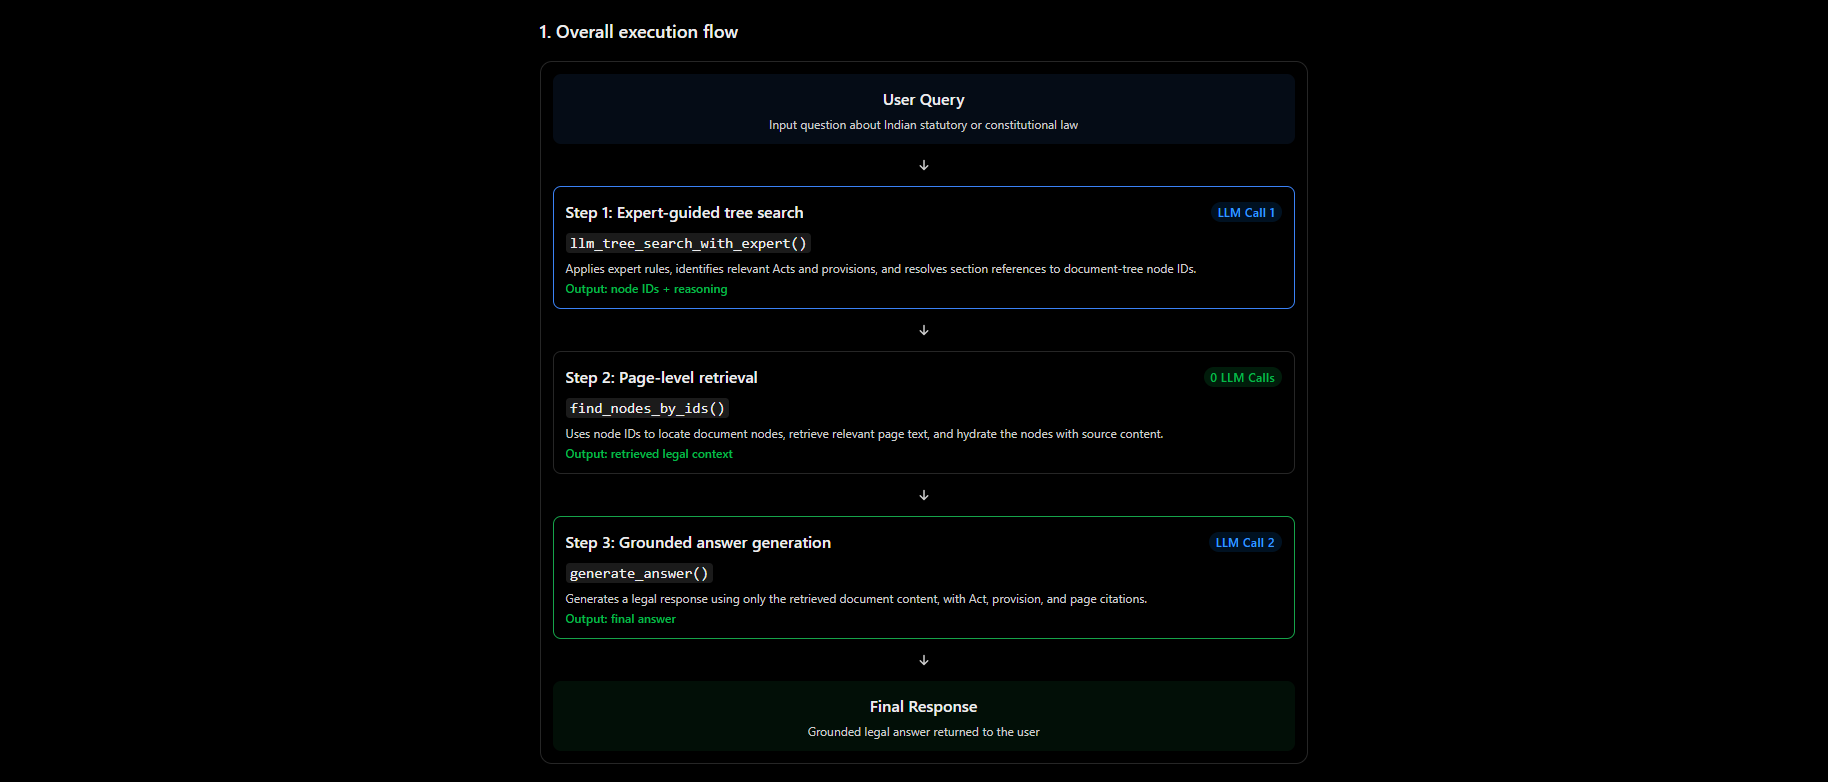

In [13]:
answer = expert_rag(
    query="Two men on a motorcycle snatched my mobile phone from my hand while I was walking on the street and sped away without hurting me. Is this ordinary theft or a separate offence under BNS 2023, and what is the punishment?",
    tree=merged_tree,
    rules=MASTER_EXPERT_RULES,
)

🔍 Query: Two men on a motorcycle snatched my mobile phone from my hand while I was walking on the street and sped away without hurting me. Is this ordinary theft or a separate offence under BNS 2023, and what is the punishment?

🧠 Reasoning: Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 303, Bharatiya Nyaya Sanhita, 2023 Section 304
🎯 Retrieved node IDs: ['bnsAct2023::0268', 'bnsAct2023::0270']
📄 Sections found: ['Bharatiya Nyaya Sanhita, 2023 — Theft.', 'Bharatiya Nyaya Sanhita, 2023 — Theft by clerk or servant of property in possession of master.']

📝 Answer:
Based on the provided context, the act of two men suddenly grabbing your mobile phone from your hand and speeding away constitutes a separate offence known as "snatching" under section 304(1) of the Bharatiya Nyaya Sanhita, 2023 (p. 200). Theft is specifically defined as snatching when an offender suddenly, quickly, or forcibly seizes, secures, grabs, or takes away movable property from a person or their possession (

In [14]:
answer = expert_rag(
    query="An intruder broke into my home at night armed with a knife, and while defending myself I caused fatal injuries to him. Under what circumstances does the right of private defence extend to causing death? What's the pusishment?",
    tree=merged_tree,
    rules=MASTER_EXPERT_RULES,
)

🔍 Query: An intruder broke into my home at night armed with a knife, and while defending myself I caused fatal injuries to him. Under what circumstances does the right of private defence extend to causing death? What's the pusishment?

🧠 Reasoning: Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 37, Bharatiya Nyaya Sanhita, 2023 Section 38, Bharatiya Nyaya Sanhita, 2023 Section 41, Bharatiya Nyaya Sanhita, 2023 Section 103
🎯 Retrieved node IDs: ['bnsAct2023::0098', 'bnsAct2023::0100', 'bnsAct2023::0151', 'bnsAct2023::0102']
📄 Sections found: ['Bharatiya Nyaya Sanhita, 2023 — When right of private defence of body extends to causing death.', 'Bharatiya Nyaya Sanhita, 2023 — When such right extends to causing any harm other than death.', 'Bharatiya Nyaya Sanhita, 2023 — Punishment for culpable homicide not amounting to murder. (intro)', 'Bharatiya Nyaya Sanhita, 2023 — CHAPTER IV']

📝 Answer:
Based on the provided text, the right of private defence of property extends to causing

In [15]:
answer = expert_rag(
    query="A business rival has threatened to file a false non-bailable criminal case against me. How can I apply for protection from arrest before an FIR is registered?",
    tree=merged_tree,
    rules=MASTER_EXPERT_RULES,
)

🔍 Query: A business rival has threatened to file a false non-bailable criminal case against me. How can I apply for protection from arrest before an FIR is registered?

🧠 Reasoning: Matched provisions: Bharatiya Nagarik Suraksha Sanhita, 2023 Section 482
🎯 Retrieved node IDs: ['bnssAct2023::0049']
📄 Sections found: ['Bharatiya Nagarik Suraksha Sanhita, 2023 — E. —Suspension, remission and commutation of sentences']

📝 Answer:
When a person has reason to believe they may be arrested on an accusation of committing a non-bailable offence, they may apply to the High Court or the Court of Session for a direction for the grant of bail (Bharatiya Nagarik Suraksha Sanhita, 2023, section 482(1), p. 146). Upon receiving such an application, the Court may direct that the person be released on bail in the event of such an arrest (Bharatiya Nagarik Suraksha Sanhita, 2023, section 482(1), p. 146). The Court may also impose specific conditions in light of the particular case, such as making oneself a

In [ ]:
answer = expert_rag(
    query="Defamatory and unlawful content targeting an individual was posted on a social media platform, and the platform ignored a government/court takedown order. Does it still enjoy intermediary immunity?",
    tree=merged_tree,
)

In [26]:
answer = expert_rag(
    query="A speeding driver hit a pedestrian at night and fled the spot without reporting the accident to the police or a Magistrate. What criminal liability and punishment apply under BNS 2023?",
    tree=merged_tree,
    rules=MASTER_EXPERT_RULES,
)

🔍 Query: A speeding driver hit a pedestrian at night and fled the spot without reporting the accident to the police or a Magistrate. What criminal liability and punishment apply under BNS 2023?
served by: gemini-3.5-flash-lite

🧠 Reasoning: Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 106
🎯 Retrieved node IDs: ['bnsAct2023::0153']
📄 Sections found: ['Bharatiya Nyaya Sanhita, 2023 — Attempt to murder.']

📝 Answer:
A speeding driver who hits a pedestrian and flees the scene without reporting the incident commits an offense by causing death through the rash and negligent driving of a vehicle (Bharatiya Nyaya Sanhita, 2023, section 106(2), p. 126). 

Under the Bharatiya Nyaya Sanhita, 2023, escaping without reporting the incident to a police officer or a Magistrate soon after causes criminal liability (section 106(2), p. 126). The prescribed punishment for this offense is imprisonment of either description for a term that may extend to ten years (Bharatiya Nyaya Sanhita, 2023,

In [ ]:
answer = expert_rag(
    query="Can you explain Section 38 of BNS?",
    tree=merged_tree,
    rules=MASTER_EXPERT_RULES,
)

In [ ]:
answer = expert_rag(
    query="Who are you",
    tree=merged_tree,
)

In [20]:
# ── Latency & failover check ─────────────────────────────────────────────────
import time

Q = ("Two men on a motorcycle snatched my mobile phone from my hand while I was walking on the street "
     "and sped away without hurting me. Is this ordinary theft or a separate offence under BNS 2023, "
     "and what is the punishment?")

# 1) Full pipeline, normal path (Gemini primary)
t0 = time.perf_counter()
expert_rag(Q, merged_tree, verbose=False)
print(f"pipeline (normal path): {time.perf_counter() - t0:.1f}s")

# 2) Failover: force the primary (Gemini) to fail so the fallback chain answers
for alias in ("tree-search", "answer"):
    t0 = time.perf_counter()
    r = router.completion(model=alias, messages=[{"role": "user", "content": "Reply with the word OK."}],
                          mock_testing_fallbacks=True)
    print(f"{alias:12s} fallback served by {r.model}  ({time.perf_counter() - t0:.1f}s)")

pipeline (normal path): 3.6s
tree-search  fallback served by nvidia/nemotron-3-ultra-550b-a55b:free  (1.8s)
answer       fallback served by openai/gpt-oss-20b  (1.5s)


In [21]:
for _ in range(3):
    r = llm_tree_search_with_expert(Q, merged_tree, expert_rules=MASTER_EXPERT_RULES)
    print(r["thinking"], r["node_list"])

Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 304, Bharatiya Nyaya Sanhita, 2023 Section 303 ['bnsAct2023::0270', 'bnsAct2023::0268']
Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 304 ['bnsAct2023::0270']
Matched provisions: Bharatiya Nyaya Sanhita, 2023 Section 304 ['bnsAct2023::0270']
